# NB21 — Feature Scaling and Gradient Descent

> **StatQuest principle: gradient descent takes steps downhill — but if the valley is a long thin canyon, it zig-zags forever. Scaling turns the canyon into a round bowl.**

---

## The main ideas are:

1. Gradient descent (NB15) minimises SSR by stepping against the gradient
2. The **shape** of the SSR bowl is set by the Hessian $H = \frac{2}{n}X^TX$
3. Its eigenvalues decide everything: the step size must satisfy $\eta < 2/\lambda_{max}$,
   and convergence speed depends on the **condition number** $\kappa = \lambda_{max}/\lambda_{min}$
4. Unscaled features → huge $\kappa$ → tiny safe step → very slow convergence
5. Standardising $x$ (mean 0, sd 1) makes $\kappa \approx 1$ → fast, robust convergence
6. Batch vs stochastic vs mini-batch GD trade exactness for speed per step
7. Scaling also changes what Ridge/Lasso penalise — the penalty depends on units


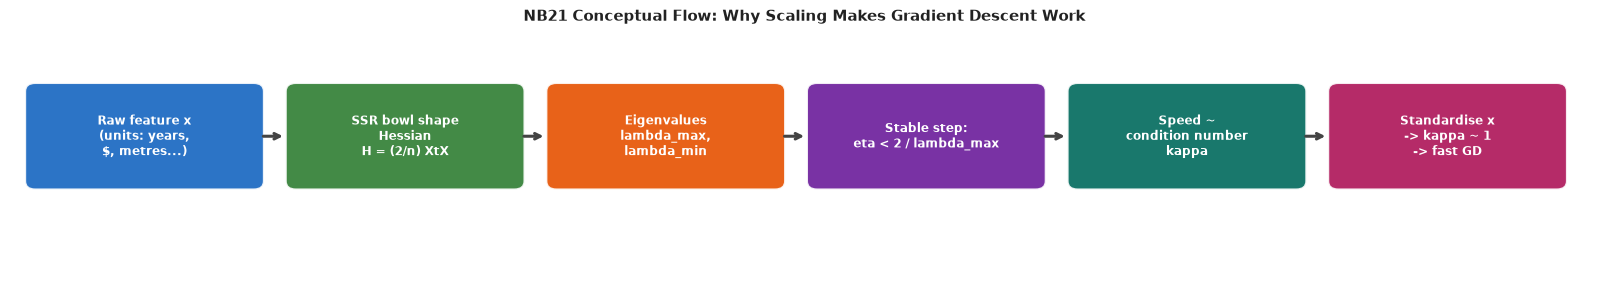

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

def flow_diagram(steps, title, colors=None, notes=None, figsize=(14, 2.8)):
    """Draw a horizontal flow diagram.  steps = list of strings."""
    n = len(steps)
    default_colors = [
        '#1565C0','#2E7D32','#E65100','#6A1B9A',
        '#00695C','#AD1457','#37474F','#4E342E',
        '#0277BD','#558B2F',
    ]
    colors = (colors or default_colors[:n]) + default_colors
    notes  = notes or [''] * n

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(-0.3, n * 3.1)
    ax.set_ylim(-1.2, 2.4)
    ax.axis('off')

    bw, bh = 2.6, 1.3
    for i, (step, color, note) in enumerate(zip(steps, colors, notes)):
        x = i * 3.1
        box = FancyBboxPatch((x, 0.2), bw, bh,
                             boxstyle="round,pad=0.12",
                             facecolor=color, edgecolor='white', linewidth=1.5, alpha=0.90)
        ax.add_patch(box)
        ax.text(x + bw/2, 0.2 + bh/2, step,
                ha='center', va='center', fontsize=8.5,
                color='white', fontweight='bold', multialignment='center')
        if note:
            ax.text(x + bw/2, 0.02, note,
                    ha='center', va='top', fontsize=7, color='#555', style='italic')
        if i < n - 1:
            ax.annotate('',
                xy=(x + bw + 0.38, 0.2 + bh/2),
                xytext=(x + bw + 0.08, 0.2 + bh/2),
                arrowprops=dict(arrowstyle='->', color='#444', lw=2.2))

    ax.set_title(title, fontsize=11, fontweight='bold', pad=6, color='#222')
    plt.tight_layout(pad=0.4)
    plt.show()

flow_diagram(
    steps=[
        'Raw feature x\n(units: years,\n$, metres...)',
        'SSR bowl shape\nHessian\nH = (2/n) XtX',
        'Eigenvalues\nlambda_max,\nlambda_min',
        'Stable step:\neta < 2 / lambda_max',
        'Speed ~\ncondition number\nkappa',
        'Standardise x\n-> kappa ~ 1\n-> fast GD',
    ],
    title='NB21 Conceptual Flow: Why Scaling Makes Gradient Descent Work',
    figsize=(16, 2.8),
)


## Step 1 — The same salary data as NB03

`X` = years of experience 1..10, `y` = salary in $1000s.
The exact OLS answer (NB03) is **b0 = 32.0000, b1 = 6.3636**.

With MSE loss $L = \frac{1}{n}\sum (y - b_0 - b_1x)^2$ the gradient is

$$\nabla L = -\frac{2}{n} X^T (y - Xb), \qquad H = \frac{2}{n}X^TX$$

where $X$ includes the column of 1s. $H$ is constant — the loss is a perfect quadratic bowl.


In [2]:
import numpy as np

X = np.arange(1, 11, dtype=float)
y = np.array([40, 45, 50, 55, 65, 70, 75, 85, 90, 95], dtype=float)
n = len(X)

Xd = np.column_stack([np.ones(n), X])
b_ols = np.linalg.lstsq(Xd, y, rcond=None)[0]
print(f"OLS (exact):  b0 = {b_ols[0]:.4f}   b1 = {b_ols[1]:.4f}")

H = 2 / n * Xd.T @ Xd
eig = np.linalg.eigvalsh(H)
print(f"\nRAW x  -> Hessian eigenvalues: {eig[0]:.4f}, {eig[1]:.4f}")
print(f"          condition number kappa = {eig[1]/eig[0]:.1f}")
print(f"          largest stable step  eta < 2/lambda_max = {2/eig[1]:.5f}")

xs = (X - X.mean()) / X.std()
Xs = np.column_stack([np.ones(n), xs])
Hs = 2 / n * Xs.T @ Xs
eig_s = np.linalg.eigvalsh(Hs)
print(f"\nSTANDARDISED x -> eigenvalues: {eig_s[0]:.4f}, {eig_s[1]:.4f}")
print(f"          condition number kappa = {eig_s[1]/eig_s[0]:.1f}")
print(f"          largest stable step  eta < {2/eig_s[1]:.5f}")


OLS (exact):  b0 = 32.0000   b1 = 6.3636

RAW x  -> Hessian eigenvalues: 0.4200, 78.5800
          condition number kappa = 187.1
          largest stable step  eta < 2/lambda_max = 0.02545

STANDARDISED x -> eigenvalues: 2.0000, 2.0000
          condition number kappa = 1.0
          largest stable step  eta < 1.00000


## Step 2 — Learning-rate sweep on RAW x (the correct story)

For a quadratic bowl the rule is exact:

| Step size | What happens |
|---|---|
| $\eta$ far below $2/\lambda_{max}$ | converges, but slowly along the flat direction |
| $\eta$ close to (but below) $2/\lambda_{max}$ | fastest convergence |
| $\eta > 2/\lambda_{max}$ | **diverges** — every step overshoots further |

Here $2/\lambda_{max} \approx 0.0255$, so 0.001 is *slow*, 0.003 is *fine*, 0.03 *diverges*.


Batch GD on RAW x, 6000 epochs (OLS SSR = 19.0909)

  lr=0.001  (slow    ) b0=  29.5500  b1= 6.7156  SSR=   31.9546
  lr=0.003  (good    ) b0=  31.9842  b1= 6.3659  SSR=   19.0914


  lr=0.03   (diverges) DIVERGED (values overflow to inf/nan)


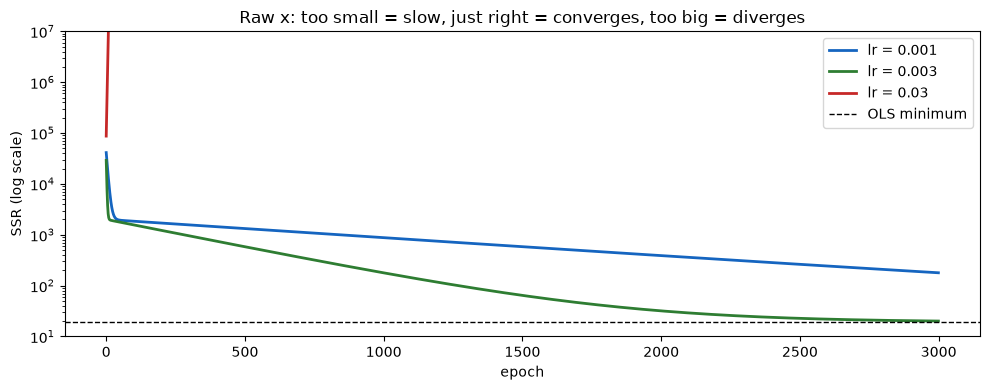

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def batch_gd(Xd, y, lr, epochs):
    b = np.zeros(Xd.shape[1])
    hist = []
    with np.errstate(over='ignore', invalid='ignore'):
        for _ in range(epochs):
            grad = -2 / len(y) * Xd.T @ (y - Xd @ b)
            b = b - lr * grad
            hist.append(np.sum((y - Xd @ b) ** 2))
    return b, np.array(hist)

epochs = 6000
print(f"Batch GD on RAW x, {epochs} epochs (OLS SSR = {np.sum((y - Xd @ b_ols)**2):.4f})\n")
results = {}
for lr, label in [(0.001, 'slow'), (0.003, 'good'), (0.03, 'diverges')]:
    b, hist = batch_gd(Xd, y, lr, epochs)
    results[lr] = hist
    if np.all(np.isfinite(b)):
        print(f"  lr={lr:<6} ({label:8s}) b0={b[0]:9.4f}  b1={b[1]:7.4f}  SSR={hist[-1]:10.4f}")
    else:
        print(f"  lr={lr:<6} ({label:8s}) DIVERGED (values overflow to inf/nan)")

fig, ax = plt.subplots(figsize=(10, 4))
for lr, c in [(0.001, '#1565C0'), (0.003, '#2E7D32'), (0.03, '#C62828')]:
    h = results[lr]
    h = np.where(np.isfinite(h) & (h < 1e12), h, np.nan)
    ax.semilogy(h[:3000], color=c, lw=2, label=f'lr = {lr}')
ax.axhline(np.sum((y - Xd @ b_ols)**2), color='k', ls='--', lw=1, label='OLS minimum')
ax.set_ylim(10, 1e7)
ax.set_xlabel('epoch'); ax.set_ylabel('SSR (log scale)')
ax.set_title('Raw x: too small = slow, just right = converges, too big = diverges')
ax.legend(); plt.tight_layout(); plt.show()


## Step 3 — Standardise x: the canyon becomes a bowl

After standardising, $\kappa \approx 1$ and a step of 0.1 (33× bigger than the best raw step) is safe.
The coefficients are in **standardised units**, so convert back:

$$b_1 = \frac{b_1^{std}}{s_x}, \qquad b_0 = b_0^{std} - b_1\,\bar x$$


In [4]:
import numpy as np

def epochs_to_converge(Xd, y, lr, tol=1e-6, max_epochs=200000):
    b = np.zeros(Xd.shape[1])
    target = np.sum((y - Xd @ np.linalg.lstsq(Xd, y, rcond=None)[0]) ** 2)
    with np.errstate(over='ignore', invalid='ignore'):
        for ep in range(1, max_epochs + 1):
            b = b - lr * (-2 / len(y) * Xd.T @ (y - Xd @ b))
            ssr = np.sum((y - Xd @ b) ** 2)
            if not np.isfinite(ssr):
                return None, b
            if ssr - target < tol * target:
                return ep, b
    return max_epochs, b

ep_raw, b_raw = epochs_to_converge(Xd, y, lr=0.02)
ep_std, b_std = epochs_to_converge(Xs, y, lr=0.1)

b1 = b_std[1] / X.std()
b0 = b_std[0] - b1 * X.mean()
print(f"RAW x,  lr=0.02 (near its limit): {ep_raw} epochs to reach the OLS SSR")
print(f"STD x,  lr=0.1                  : {ep_std} epochs")
print(f"Speed-up: {ep_raw/ep_std:.0f}x fewer epochs")
print(f"\nBack-transformed from standardised fit: b0 = {b0:.4f}, b1 = {b1:.4f}  (OLS: 32.0000, 6.3636)")


RAW x,  lr=0.02 (near its limit): 1095 epochs to reach the OLS SSR
STD x,  lr=0.1                  : 49 epochs
Speed-up: 22x fewer epochs

Back-transformed from standardised fit: b0 = 31.9994, b1 = 6.3635  (OLS: 32.0000, 6.3636)


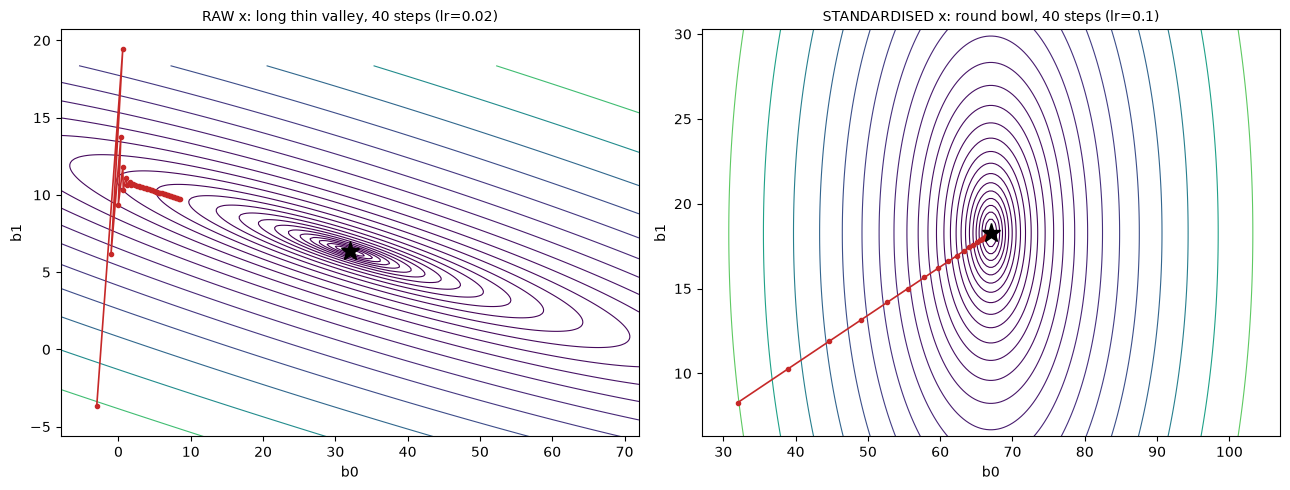

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def contour_panel(ax, Xmat, title, lr, steps):
    bopt = np.linalg.lstsq(Xmat, y, rcond=None)[0]
    g0 = np.linspace(bopt[0] - 40, bopt[0] + 40, 200)
    g1 = np.linspace(bopt[1] - 12, bopt[1] + 12, 200)
    B0, B1 = np.meshgrid(g0, g1)
    L = ((y[None, None, :] - B0[..., None] - B1[..., None] * Xmat[:, 1][None, None, :]) ** 2).mean(-1)
    ax.contour(B0, B1, L, levels=np.geomspace(L.min() + 1e-3, L.max(), 25), cmap='viridis', linewidths=0.8)
    b = np.array([bopt[0] - 35, bopt[1] - 10.0])
    path = [b.copy()]
    for _ in range(steps):
        b = b - lr * (-2 / len(y) * Xmat.T @ (y - Xmat @ b))
        path.append(b.copy())
    path = np.array(path)
    ax.plot(path[:, 0], path[:, 1], 'o-', color='#C62828', ms=3, lw=1.2)
    ax.plot(*bopt, 'k*', ms=14)
    ax.set_title(title, fontsize=10); ax.set_xlabel('b0'); ax.set_ylabel('b1')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
contour_panel(axes[0], Xd, 'RAW x: long thin valley, 40 steps (lr=0.02)', 0.02, 40)
contour_panel(axes[1], Xs, 'STANDARDISED x: round bowl, 40 steps (lr=0.1)', 0.1, 40)
plt.tight_layout(); plt.show()


## Step 4 — Batch vs Stochastic vs Mini-batch gradient descent

| Variant | Gradient uses | Cost per step | Path |
|---|---|---|---|
| **Batch** | all n rows | O(n·p) | smooth, exact gradient |
| **Stochastic (SGD)** | 1 random row | O(p) | noisy, needs decaying lr |
| **Mini-batch** | b rows (e.g. 32) | O(b·p) | the practical default (GPUs, big data) |

We use a larger synthetic problem (n = 5,000, true b0 = 4, b1 = 3, standardised x) so the difference is visible.


OLS exact          : b0=3.9873  b1=2.9946  MSE=0.9972
Batch (50 epochs)  : b0=3.9872  b1=2.9946  MSE=0.9972  updates=50
SGD (1 epoch)      : b0=4.0387  b1=3.0012  MSE=0.9998  updates=5000
Mini-batch 32 (2 ep): b0=3.9757  b1=2.9426  MSE=0.9999  updates=314


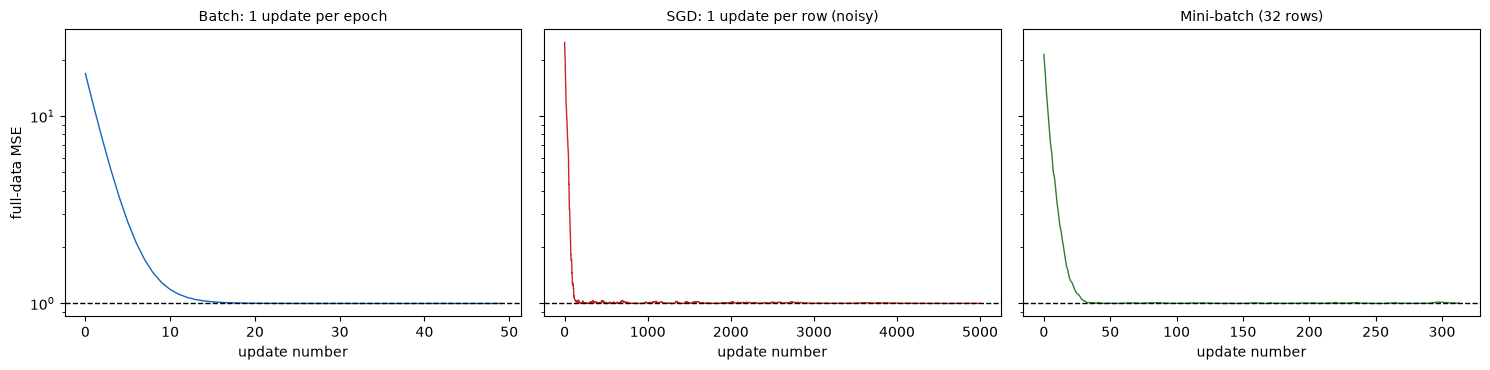

In [6]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(21)
N = 5000
xb = rng.normal(0, 1, N)
yb = 4 + 3 * xb + rng.normal(0, 1, N)
Xb = np.column_stack([np.ones(N), xb])
b_true_ols = np.linalg.lstsq(Xb, yb, rcond=None)[0]

def run(batch, lr0, epochs=5, decay=False, seed=0):
    r = np.random.default_rng(seed)
    b = np.zeros(2); losses = []; t = 0
    for ep in range(epochs):
        idx = r.permutation(N)
        for s in range(0, N, batch):
            j = idx[s:s + batch]
            lr = lr0 / (1 + 0.001 * t) if decay else lr0
            b = b - lr * (-2 / len(j) * Xb[j].T @ (yb[j] - Xb[j] @ b))
            t += 1
            losses.append(np.mean((yb - Xb @ b) ** 2))
    return b, np.array(losses), t

b_batch, l_batch, u_batch = run(N, 0.1, epochs=50)
b_sgd, l_sgd, u_sgd = run(1, 0.01, epochs=1, decay=True)
b_mini, l_mini, u_mini = run(32, 0.05, epochs=2)

print(f"OLS exact          : b0={b_true_ols[0]:.4f}  b1={b_true_ols[1]:.4f}  MSE={np.mean((yb - Xb @ b_true_ols)**2):.4f}")
for name, b, l, u in [('Batch (50 epochs)', b_batch, l_batch, u_batch),
                      ('SGD (1 epoch)', b_sgd, l_sgd, u_sgd),
                      ('Mini-batch 32 (2 ep)', b_mini, l_mini, u_mini)]:
    print(f"{name:19s}: b0={b[0]:.4f}  b1={b[1]:.4f}  MSE={l[-1]:.4f}  updates={u}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (name, l, c) in zip(axes, [('Batch: 1 update per epoch', l_batch, '#1565C0'),
                                   ('SGD: 1 update per row (noisy)', l_sgd, '#C62828'),
                                   ('Mini-batch (32 rows)', l_mini, '#2E7D32')]):
    ax.plot(l, color=c, lw=1); ax.set_yscale('log'); ax.set_title(name, fontsize=10)
    ax.set_xlabel('update number'); ax.axhline(np.mean((yb - Xb @ b_true_ols)**2), color='k', ls='--', lw=1)
axes[0].set_ylabel('full-data MSE')
plt.tight_layout(); plt.show()


## Step 5 — Scaling changes what Ridge and Lasso penalise

Ridge minimises $SSR + \lambda\sum b_j^2$. A coefficient's size depends on the **units** of its feature:
measure income in $ instead of $1000s and its slope becomes 1000× smaller — so it is penalised a million times less.
Without scaling, the penalty is arbitrary. **Always standardise before Ridge/Lasso/ElasticNet** (in a Pipeline, NB20).


In [7]:
import numpy as np
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(3)
n = 200
income_k = rng.normal(50, 15, n)              # income in $1000s
age = rng.normal(40, 10, n)                   # age in years
yy = 2.0 * income_k + 1.5 * age + rng.normal(0, 10, n)

def fit(Xm, scaled):
    if scaled:
        Xm = StandardScaler().fit_transform(Xm)
    return Ridge(alpha=5000).fit(Xm, yy).coef_

X_k = np.column_stack([income_k, age])
X_dollars = np.column_stack([income_k * 1000, age])

print("OLS slopes (income in $k):", LinearRegression().fit(X_k, yy).coef_.round(4))
print("\nRidge(alpha=5000), NO scaling:")
print("  income in $1000s ->", fit(X_k, False).round(4))
c = fit(X_dollars, False)
print("  income in dollars ->", c.round(6), "  (= per $1000:", round(c[0] * 1000, 4), ")")
print("\nRidge(alpha=5000), WITH StandardScaler:")
print("  income in $1000s ->", fit(X_k, True).round(4))
print("  income in dollars ->", fit(X_dollars, True).round(4), " <- identical: units no longer matter")


OLS slopes (income in $k): [1.9338 1.4814]

Ridge(alpha=5000), NO scaling:
  income in $1000s -> [1.7562 1.1853]
  income in dollars -> [0.00194  1.177679]   (= per $1000: 1.9402 )

Ridge(alpha=5000), WITH StandardScaler:
  income in $1000s -> [1.1671 0.5979]
  income in dollars -> [1.1671 0.5979]  <- identical: units no longer matter


## Key Takeaways

| Concept | What to remember |
|---|---|
| Hessian | $H=\frac{2}{n}X^TX$ is fixed for linear regression: the loss is a perfect bowl |
| Stability | Gradient descent converges only if $\eta < 2/\lambda_{max}$ |
| Speed | Number of steps grows with the condition number $\kappa=\lambda_{max}/\lambda_{min}$ |
| Scaling | Standardising x makes $\kappa \approx 1$ → larger safe steps, far fewer epochs |
| Variants | Batch = exact & smooth; SGD = cheap & noisy (decay lr); mini-batch = practical default |
| Penalties | Ridge/Lasso penalties depend on units → standardise first, inside a Pipeline |
| Correction to NB15 | With raw x, lr = 0.003 converges (best of the three); lr = 0.03 is the one that diverges |
